# UCS420 Cognitive Computing – Assignment 10
## Diabetes Care Information Assistant (Healthcare Cognitive Assistant)

A Python-based cognitive assistant that **understands** user queries (NLP), **identifies intent** (TF-IDF + ML classifier),
**reasons** over them (rule engine) and **retrieves** answers from a domain knowledge base.

| # | Requirement | Section |
|---|---|---|
| 1 | Labelled corpus ≥ 40 queries, ≥ 5 intents | §1 (105 queries, 7 intents) |
| 2 | Hierarchical taxonomy, ≥ 4 major categories × ≥ 2 subcategories | §2 |
| 3 | ≥ 8 domain concepts, ≥ 10 relationships | §3 (14 concepts, 18 relationships) |
| 4 | Lowercase, tokenization, stopword removal, lemmatization | §4 |
| 5 | TF-IDF + Naive Bayes / Logistic Regression / SVM | §5 |
| 6 | Accuracy, precision, recall, F1, confusion matrix | §6 |
| 7 | Domain knowledge base for every intent | §7 |
| 8 | ≥ 5 rules incl. emergency, low-confidence, unsupported | §8 (8 rules) |
| 9 | Integrated assistant (NLP + classifier + reasoning + retrieval) | §9 |
| 10 | Google Colab interactive interface (multiple queries) | §10 |
| Tests | Each intent, paraphrase, unsupported, low-confidence, emergency | §11 |

> ⚠️ Educational assistant only – it does not replace a doctor.

In [1]:
# Setup (works in Google Colab and local Jupyter)
%pip -q install nltk scikit-learn seaborn networkx ipywidgets

import re, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns, networkx as nx
import nltk
warnings.filterwarnings("ignore")
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)
random.seed(42); np.random.seed(42)
print("Setup complete")


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\Vineet\AppData\Local\Temp\6a0157398677c19c\0f5ec00a-a11e-4a5a-8a37-f29f4700c713\scratchpad\venv\Scripts\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


Setup complete


## 1. Labelled Query Corpus (105 queries · 7 intent categories)

In [2]:
corpus = {
 "symptoms": [
  "What are the common symptoms of diabetes?",
  "Why am I always thirsty and urinating frequently?",
  "What are the early warning signs of high blood sugar?",
  "Can blurred vision be a sign of diabetes?",
  "I feel tired all the time and lose weight without trying, is it diabetes?",
  "What symptoms indicate type 1 diabetes in children?",
  "Is frequent hunger a symptom of diabetes?",
  "Do slow healing cuts and sores mean I have diabetes?",
  "What does low blood sugar feel like?",
  "What are the signs of hypoglycemia like shaking and sweating?",
  "What are the symptoms of type 2 diabetes in adults?",
  "Why do I feel numb and tingling with frequent thirst?",
  "Is feeling dizzy and sweaty a sign of low sugar?",
  "How do I know if I have high blood sugar symptoms?",
  "Can itchy skin and frequent infections be diabetes symptoms?"],
 "diet_nutrition": [
  "What foods should a diabetic person eat?",
  "Which foods should I avoid if I have diabetes?",
  "Can diabetics eat fruits like mango and banana?",
  "Is rice bad for people with diabetes?",
  "How many carbohydrates should I eat per meal?",
  "What is the glycemic index and why does it matter?",
  "Can I drink alcohol if I am diabetic?",
  "Is sugar free food and artificial sweetener safe for diabetes?",
  "Suggest a healthy breakfast for a diabetic patient",
  "What is carb counting in a diabetes diet plan?",
  "Is brown rice better than white rice for diabetics?",
  "What snacks are healthy for people with diabetes?",
  "Can diabetics eat sweets or chocolate occasionally?",
  "What should be on a diabetic dinner plate?",
  "Are dates and honey safe to eat with diabetes?"],
 "blood_sugar_monitoring": [
  "What is a normal blood sugar level?",
  "How often should I check my blood glucose?",
  "What is HbA1c and what should my target be?",
  "How do I use a glucometer correctly?",
  "What is a continuous glucose monitor?",
  "What is the normal fasting sugar level?",
  "When should I test my sugar after meals?",
  "What does a high HbA1c reading mean?",
  "How do I keep a log of my glucose readings?",
  "What is the target blood sugar range before meals?",
  "What should my sugar reading be two hours after eating?",
  "How accurate are glucose meters and test strips?",
  "Is a fasting glucose reading of 110 normal?",
  "What is the ideal HbA1c for a diabetic?",
  "How do I test my blood sugar at home?"],
 "medication_insulin": [
  "How does metformin work?",
  "What are the side effects of metformin?",
  "How do I inject insulin properly?",
  "What are the different types of insulin?",
  "Can I skip my diabetes medicine for a day?",
  "What happens if I miss an insulin dose?",
  "How should insulin be stored?",
  "Which tablets are used to treat type 2 diabetes?",
  "Should I take metformin with food?",
  "What is the difference between long acting and rapid acting insulin?",
  "What is the right dose of insulin for me?",
  "Can metformin cause stomach upset or diarrhoea?",
  "Which insulin pen or syringe should I use?",
  "Are SGLT2 inhibitor tablets good for diabetes?",
  "What time of day should I take my diabetes tablets?"],
 "exercise_lifestyle": [
  "What exercises are good for diabetes?",
  "How much physical activity should a diabetic do weekly?",
  "Can walking help lower blood sugar?",
  "Is yoga beneficial for diabetes control?",
  "Should I check my sugar before a workout?",
  "How does stress affect diabetes?",
  "Does sleep affect blood sugar control?",
  "How can I lose weight to manage type 2 diabetes?",
  "Is weight training safe for diabetics?",
  "Does smoking make diabetes worse?",
  "How many minutes should I walk daily with diabetes?",
  "Is running or jogging good for diabetic people?",
  "Can meditation reduce my blood sugar?",
  "What lifestyle changes help control diabetes?",
  "Is swimming a good workout for diabetes?"],
 "complications": [
  "What are the long term complications of diabetes?",
  "How does diabetes affect the kidneys?",
  "Can diabetes cause blindness?",
  "What is diabetic neuropathy?",
  "Why do diabetics need special foot care?",
  "What is diabetic ketoacidosis?",
  "Does diabetes increase the risk of heart disease and stroke?",
  "What is diabetic retinopathy?",
  "How can I prevent nerve damage from diabetes?",
  "What causes diabetic foot ulcers?",
  "Can diabetes damage my eyes?",
  "What is diabetic nephropathy and kidney failure?",
  "Why do diabetics get numbness in their feet?",
  "How often should diabetics get an eye and kidney checkup?",
  "Can diabetes lead to amputation?"],
 "types_diagnosis": [
  "What is the difference between type 1 and type 2 diabetes?",
  "What is gestational diabetes?",
  "What is prediabetes?",
  "How is diabetes diagnosed?",
  "Which tests confirm diabetes?",
  "Is diabetes hereditary?",
  "What causes type 2 diabetes?",
  "Can type 2 diabetes be reversed?",
  "At what HbA1c level is diabetes diagnosed?",
  "Who is at risk of developing diabetes?",
  "What test is used to diagnose type 2 diabetes?",
  "Can children get type 1 diabetes?",
  "What is an oral glucose tolerance test?",
  "Does obesity cause diabetes?",
  "Is prediabetes curable?"],
}
df = pd.DataFrame([(q, intent) for intent, qs in corpus.items() for q in qs], columns=["query", "intent"])
print("Total queries:", len(df), "| Intent categories:", df.intent.nunique())
display(df.intent.value_counts().rename("count").to_frame())
df.sample(8, random_state=1)

Total queries: 105 | Intent categories: 7


,count
intent,
symptoms,15
diet_nutrition,15
blood_sugar_monitoring,15
medication_insulin,15
exercise_lifestyle,15
complications,15
types_diagnosis,15


,query,intent
65,How does stress affect diabetes?,exercise_lifestyle
35,What is the normal fasting sugar level?,blood_sugar_monitoring
42,Is a fasting glucose reading of 110 normal?,blood_sugar_monitoring
93,How is diabetes diagnosed?,types_diagnosis
38,How do I keep a log of my glucose readings?,blood_sugar_monitoring
39,What is the target blood sugar range before me...,blood_sugar_monitoring
54,What is the difference between long acting and...,medication_insulin
86,What is diabetic nephropathy and kidney failure?,complications


## 2. Hierarchical Taxonomy (5 major categories, 2 subcategories each)
Every intent is mapped to a node of the taxonomy so the assistant can tell the user *where* their question sits in the domain.

In [3]:
taxonomy = {
 "Diabetes Care": {
  "1. Understanding Diabetes": {
     "1.1 Types & Diagnosis": ["Type 1", "Type 2", "Gestational", "Prediabetes", "Diagnostic tests (FPG, OGTT, HbA1c)"],
     "1.2 Symptoms & Warning Signs": ["Hyperglycemia signs", "Hypoglycemia signs"]},
  "2. Clinical Management": {
     "2.1 Blood Sugar Monitoring": ["Glucometer (SMBG)", "CGM", "HbA1c targets"],
     "2.2 Medication & Insulin": ["Oral drugs (Metformin, SGLT2i, DPP-4i)", "Insulin types", "Injection & storage"]},
  "3. Lifestyle Management": {
     "3.1 Diet & Nutrition": ["Carb counting", "Glycemic index", "Plate method"],
     "3.2 Exercise & Wellbeing": ["Aerobic exercise", "Resistance training", "Sleep, stress, smoking"]},
  "4. Complications": {
     "4.1 Acute Complications": ["Hypoglycemia", "Diabetic ketoacidosis (DKA)", "Hyperosmolar state"],
     "4.2 Chronic Complications": ["Neuropathy", "Retinopathy", "Nephropathy", "Cardiovascular disease", "Foot ulcers"]},
  "5. Safety & Escalation": {
     "5.1 Emergencies": ["Severe hypoglycemia", "Unconsciousness / seizure", "DKA symptoms"],
     "5.2 Out-of-scope Queries": ["Non-diabetes health topics", "Non-health topics"]},
 }
}
intent_to_taxonomy = {
 "types_diagnosis":        "Diabetes Care > Understanding Diabetes > Types & Diagnosis",
 "symptoms":               "Diabetes Care > Understanding Diabetes > Symptoms & Warning Signs",
 "blood_sugar_monitoring": "Diabetes Care > Clinical Management > Blood Sugar Monitoring",
 "medication_insulin":     "Diabetes Care > Clinical Management > Medication & Insulin",
 "diet_nutrition":         "Diabetes Care > Lifestyle Management > Diet & Nutrition",
 "exercise_lifestyle":     "Diabetes Care > Lifestyle Management > Exercise & Wellbeing",
 "complications":          "Diabetes Care > Complications > Acute / Chronic Complications",
}
def print_tree(node, indent=0):
    for k, v in node.items():
        print("    " * indent + ("📁 " if indent < 2 else "📂 ") + k)
        if isinstance(v, dict): print_tree(v, indent + 1)
        else:
            for leaf in v: print("    " * (indent + 1) + "• " + leaf)
print_tree(taxonomy)

📁 Diabetes Care
    📁 1. Understanding Diabetes
        📂 1.1 Types & Diagnosis
            • Type 1
            • Type 2
            • Gestational
            • Prediabetes
            • Diagnostic tests (FPG, OGTT, HbA1c)
        📂 1.2 Symptoms & Warning Signs
            • Hyperglycemia signs
            • Hypoglycemia signs
    📁 2. Clinical Management
        📂 2.1 Blood Sugar Monitoring
            • Glucometer (SMBG)
            • CGM
            • HbA1c targets
        📂 2.2 Medication & Insulin
            • Oral drugs (Metformin, SGLT2i, DPP-4i)
            • Insulin types
            • Injection & storage
    📁 3. Lifestyle Management
        📂 3.1 Diet & Nutrition
            • Carb counting
            • Glycemic index
            • Plate method
        📂 3.2 Exercise & Wellbeing
            • Aerobic exercise
            • Resistance training
            • Sleep, stress, smoking
    📁 4. Complications
        📂 4.1 Acute Complications
            • Hypoglycemia
          

## 3. Domain Concepts & Relationships (Ontology / Knowledge Graph)
14 domain concepts and 18 labelled relationships (subject –relation→ object).

Concepts: 14 | Relationships: 18


,Subject,Relation,Object
0,Pancreas,produces,Insulin
1,Insulin,lowers,Blood Glucose
2,Diabetes,is characterised by,Hyperglycemia
3,Hyperglycemia,is elevated,Blood Glucose
4,HbA1c,measures 3-month average,Blood Glucose
5,Metformin,treats,Diabetes
6,Metformin,reduces,Blood Glucose
7,Carbohydrates,raise,Blood Glucose
8,Exercise,improves sensitivity to,Insulin
9,Exercise,lowers,Blood Glucose


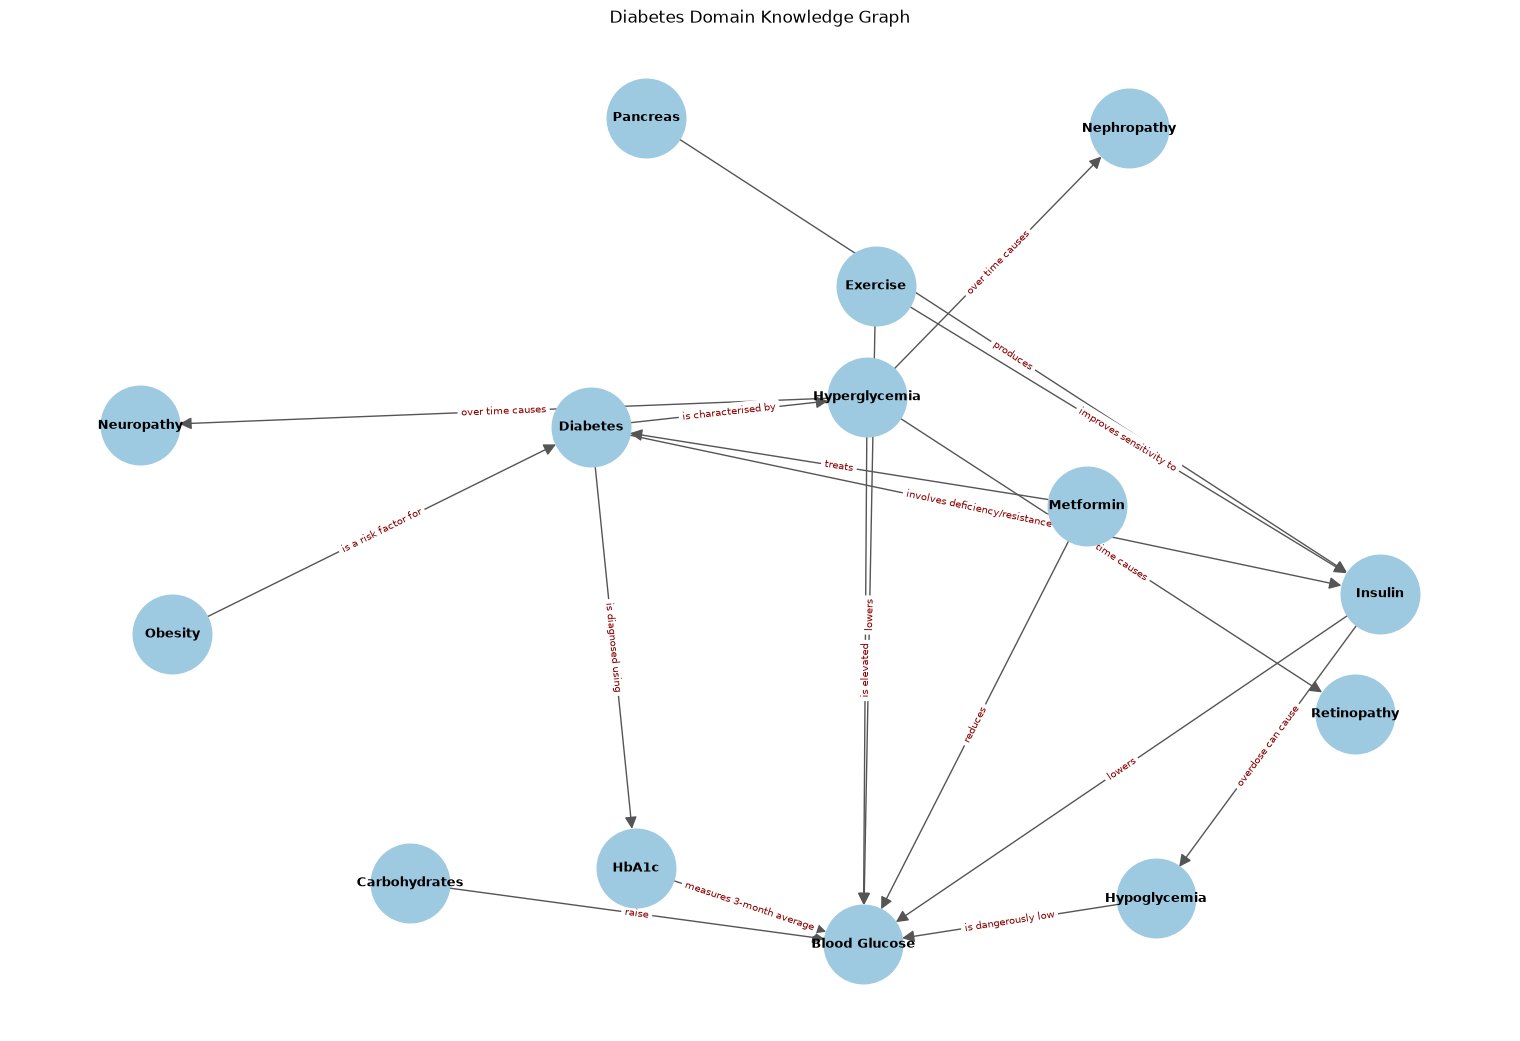

Ontology query 'Insulin': ['Pancreas produces Insulin', 'Insulin lowers Blood Glucose', 'Exercise improves sensitivity to Insulin', 'Insulin overdose can cause Hypoglycemia', 'Diabetes involves deficiency/resistance of Insulin']


In [4]:
concepts = ["Diabetes", "Pancreas", "Insulin", "Blood Glucose", "HbA1c", "Metformin", "Carbohydrates",
            "Exercise", "Obesity", "Hypoglycemia", "Hyperglycemia", "Neuropathy", "Retinopathy", "Nephropathy"]
relationships = [
 ("Pancreas", "produces", "Insulin"),
 ("Insulin", "lowers", "Blood Glucose"),
 ("Diabetes", "is characterised by", "Hyperglycemia"),
 ("Hyperglycemia", "is elevated", "Blood Glucose"),
 ("HbA1c", "measures 3-month average", "Blood Glucose"),
 ("Metformin", "treats", "Diabetes"),
 ("Metformin", "reduces", "Blood Glucose"),
 ("Carbohydrates", "raise", "Blood Glucose"),
 ("Exercise", "improves sensitivity to", "Insulin"),
 ("Exercise", "lowers", "Blood Glucose"),
 ("Obesity", "is a risk factor for", "Diabetes"),
 ("Insulin", "overdose can cause", "Hypoglycemia"),
 ("Hypoglycemia", "is dangerously low", "Blood Glucose"),
 ("Hyperglycemia", "over time causes", "Neuropathy"),
 ("Hyperglycemia", "over time causes", "Retinopathy"),
 ("Hyperglycemia", "over time causes", "Nephropathy"),
 ("Diabetes", "is diagnosed using", "HbA1c"),
 ("Diabetes", "involves deficiency/resistance of", "Insulin"),
]
print(f"Concepts: {len(concepts)} | Relationships: {len(relationships)}")
display(pd.DataFrame(relationships, columns=["Subject", "Relation", "Object"]))

G = nx.DiGraph()
G.add_nodes_from(concepts)
for s, r, o in relationships: G.add_edge(s, o, label=r)
plt.figure(figsize=(15, 10))
pos = nx.spring_layout(G, k=1.6, seed=7)
nx.draw(G, pos, with_labels=True, node_color="#9ecae1", node_size=3200, font_size=9,
        font_weight="bold", arrowsize=18, edge_color="#555")
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "label"), font_size=7, font_color="darkred")
plt.title("Diabetes Domain Knowledge Graph"); plt.show()

def related_facts(concept):
    """Query the ontology: all relationships touching a concept."""
    return [f"{s} {r} {o}" for s, r, o in relationships if concept in (s, o)]
print("Ontology query 'Insulin':", related_facts("Insulin"))

## 4. NLP Preprocessing Pipeline
Lowercase → tokenization → stopword removal → lemmatization (NLTK).
Negation / question words that matter for meaning (`not`, `no`, `how`, `what`, `when`) are kept.

In [5]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

STOP = set(stopwords.words("english")) - {"not", "no", "how", "what", "when", "should", "can"}
lemmatizer = WordNetLemmatizer()

def preprocess(text, verbose=False):
    lower = text.lower()                                           # 1. lowercase
    tokens = word_tokenize(lower)                                  # 2. tokenization
    tokens = [t for t in tokens if re.fullmatch(r"[a-z0-9]+", t)]  #    drop punctuation
    no_stop = [t for t in tokens if t not in STOP]                 # 3. stopword removal
    lemmas = [lemmatizer.lemmatize(lemmatizer.lemmatize(t, "v"), "n") for t in no_stop]  # 4. lemmatization
    if verbose:
        print("Original   :", text); print("Lowercase  :", lower); print("Tokens     :", tokens)
        print("No stopword:", no_stop); print("Lemmatized :", lemmas)
    return " ".join(lemmas)

_ = preprocess("What are the side effects of Metformin tablets when taken daily?", verbose=True)
df["clean"] = df["query"].apply(preprocess)
df.head()

Original   : What are the side effects of Metformin tablets when taken daily?
Lowercase  : what are the side effects of metformin tablets when taken daily?
Tokens     : ['what', 'are', 'the', 'side', 'effects', 'of', 'metformin', 'tablets', 'when', 'taken', 'daily']
No stopword: ['what', 'side', 'effects', 'metformin', 'tablets', 'when', 'taken', 'daily']
Lemmatized : ['what', 'side', 'effect', 'metformin', 'tablet', 'when', 'take', 'daily']


,query,intent,clean
0,What are the common symptoms of diabetes?,symptoms,what common symptom diabetes
1,Why am I always thirsty and urinating frequently?,symptoms,always thirsty urinate frequently
2,What are the early warning signs of high blood...,symptoms,what early warn sign high blood sugar
3,Can blurred vision be a sign of diabetes?,symptoms,can blur vision sign diabetes
4,I feel tired all the time and lose weight with...,symptoms,feel tire time lose weight without try diabetes


## 5. Feature Extraction (TF-IDF) & Classifier Training
TF-IDF with unigrams + bigrams. Three classifiers are compared (Multinomial Naive Bayes, Logistic Regression, Linear SVM) using a stratified train/test split and 5-fold cross-validation.
Logistic Regression is used in the final assistant because it gives calibrated class **probabilities** needed for the low-confidence rule.

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

X_train, X_test, y_train, y_test = train_test_split(df["clean"], df["intent"], test_size=0.25,
                                                    stratify=df["intent"], random_state=42)
def make_tfidf(): return TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
models = {
 "Naive Bayes":         Pipeline([("tfidf", make_tfidf()), ("clf", MultinomialNB(alpha=0.3))]),
 "Logistic Regression": Pipeline([("tfidf", make_tfidf()), ("clf", LogisticRegression(C=20, max_iter=2000))]),
 "Linear SVM":          Pipeline([("tfidf", make_tfidf()), ("clf", LinearSVC(C=1.0))]),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    rows.append([name, m.score(X_test, y_test), cross_val_score(m, df["clean"], df["intent"], cv=cv).mean()])
cmp = pd.DataFrame(rows, columns=["Model", "Test accuracy", "5-fold CV accuracy"]).round(3)
display(cmp)

vec = models["Logistic Regression"].named_steps["tfidf"]
print("TF-IDF feature matrix shape (train):", vec.transform(X_train).shape)
print("Sample features:", vec.get_feature_names_out()[:25])

,Model,Test accuracy,5-fold CV accuracy
0,Naive Bayes,0.704,0.724
1,Logistic Regression,0.704,0.705
2,Linear SVM,0.704,0.695


TF-IDF feature matrix shape (train): (78, 441)
Sample features: ['accurate' 'accurate glucose' 'act' 'act insulin' 'act rapid' 'adult'
 'affect' 'affect blood' 'affect diabetes' 'alcohol' 'alcohol diabetic'
 'amputation' 'artificial' 'artificial sweetener' 'avoid' 'avoid diabetes'
 'bad' 'bad people' 'better' 'better white' 'blindness' 'blood'
 'blood glucose' 'blood sugar' 'blur']


## 6. Model Evaluation – Accuracy, Precision, Recall, F1-score, Confusion Matrix

Accuracy : 0.704
Precision: 0.717 (macro)
Recall   : 0.714 (macro)
F1-score : 0.695 (macro)

                        precision    recall  f1-score   support

blood_sugar_monitoring       0.60      1.00      0.75         3
         complications       0.67      0.50      0.57         4
        diet_nutrition       0.50      0.75      0.60         4
    exercise_lifestyle       0.50      0.25      0.33         4
    medication_insulin       1.00      1.00      1.00         4
              symptoms       1.00      0.75      0.86         4
       types_diagnosis       0.75      0.75      0.75         4

              accuracy                           0.70        27
             macro avg       0.72      0.71      0.69        27
          weighted avg       0.72      0.70      0.69        27



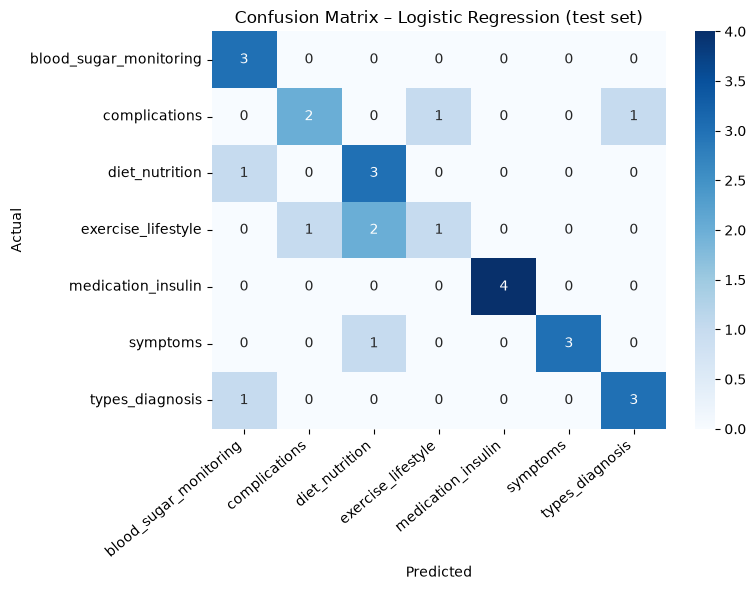

,Model,Accuracy,Precision,Recall,F1
0,Naive Bayes,0.704,0.793,0.714,0.690
1,Logistic Regression,0.704,0.717,0.714,0.695
2,Linear SVM,0.704,0.700,0.714,0.693


Final model trained on all 105 queries


In [7]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

clf = models["Logistic Regression"]
y_pred = clf.predict(X_test)
acc = accuracy_score(y_test, y_pred)
p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
print(f"Accuracy : {acc:.3f}\nPrecision: {p:.3f} (macro)\nRecall   : {r:.3f} (macro)\nF1-score : {f:.3f} (macro)\n")
print(classification_report(y_test, y_pred, zero_division=0))

labels = sorted(df.intent.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix – Logistic Regression (test set)"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

# Metrics for all three classifiers
summary = []
for name, m in models.items():
    yp = m.predict(X_test)
    pp, rr, ff, _ = precision_recall_fscore_support(y_test, yp, average="macro", zero_division=0)
    summary.append([name, accuracy_score(y_test, yp), pp, rr, ff])
display(pd.DataFrame(summary, columns=["Model", "Accuracy", "Precision", "Recall", "F1"]).round(3))

# Retrain the final model on the full corpus for deployment
final_model = Pipeline([("tfidf", make_tfidf()), ("clf", LogisticRegression(C=20, max_iter=2000))])
final_model.fit(df["clean"], df["intent"])
VOCAB = set(final_model.named_steps["tfidf"].vocabulary_)
print("Final model trained on all", len(df), "queries")

## 7. Domain Knowledge Base
Each intent has a summary, a set of facts (retrieved by TF-IDF cosine similarity to the query) and a trusted source.

In [8]:
knowledge_base = {
 "symptoms": {
  "summary": "Common symptoms of high blood sugar include excessive thirst, frequent urination, increased hunger, tiredness, blurred vision and unexplained weight loss.",
  "facts": [
   "Feeling very thirsty (polydipsia) and needing to pee / urinate a lot, even at night (polyuria), happen because the kidneys flush out extra glucose with water.",
   "Unexplained weight loss and constant hunger can occur because cells cannot use glucose for energy without enough insulin.",
   "Blurred vision, fatigue, and slow-healing cuts or sores are warning signs of persistently high blood sugar.",
   "Type 1 diabetes symptoms in children often appear quickly over weeks: thirst, bedwetting, weight loss, tiredness and irritability.",
   "Low blood sugar (hypoglycemia) feels like shaking, sweating, fast heartbeat, hunger, dizziness, confusion or irritability."],
  "source": "WHO / American Diabetes Association (ADA)"},
 "diet_nutrition": {
  "summary": "A diabetes-friendly diet focuses on vegetables, whole grains, lean protein, healthy fats and controlled carbohydrate portions.",
  "facts": [
   "Use the plate method: half non-starchy vegetables, a quarter lean protein, a quarter whole-grain carbohydrates.",
   "Avoid or limit sugary drinks, sweets, refined white rice/bread, fried foods and highly processed snacks.",
   "Fruits like mango and banana can be eaten in small portions; whole fruit is better than juice because fibre slows sugar absorption.",
   "The glycemic index (GI) ranks how fast a food raises blood glucose; low-GI foods (oats, lentils, most vegetables) are preferred.",
   "Carb counting means tracking grams of carbohydrate per meal (often about 45–60 g for many adults) to match medication and keep sugar stable.",
   "Alcohol can cause delayed low blood sugar, especially with insulin or sulfonylureas – drink only in moderation and with food.",
   "Artificial sweeteners are generally considered safe in moderation, but 'sugar-free' foods may still contain carbohydrates and calories.",
   "A healthy diabetic breakfast example: vegetable oats or besan chilla with curd, or eggs with whole-grain toast and vegetables."],
  "source": "ADA Standards of Care – Nutrition"},
 "blood_sugar_monitoring": {
  "summary": "Typical targets for many adults with diabetes: 80–130 mg/dL before meals, below 180 mg/dL two hours after meals and HbA1c below 7%.",
  "facts": [
   "Normal fasting blood sugar (without diabetes) is 70–99 mg/dL; 100–125 mg/dL suggests prediabetes.",
   "HbA1c reflects average blood glucose over about 3 months; a common target for adults with diabetes is below 7%.",
   "A high HbA1c means blood sugar has been elevated for months and increases the risk of complications – treatment may need review.",
   "To use a glucometer: wash and dry hands, insert a strip, prick the side of the fingertip, apply the blood drop and record the reading.",
   "A continuous glucose monitor (CGM) uses a small sensor under the skin to measure glucose every few minutes and shows trends and alerts.",
   "Check after meals at about 2 hours from the first bite; a common target is below 180 mg/dL.",
   "Frequency of testing depends on treatment: people on insulin may test several times daily, others less often as advised by their doctor.",
   "Keep a logbook or app recording date, time, reading, meals, medicines and activity to share with your doctor."],
  "source": "ADA Standards of Care – Glycemic Targets"},
 "medication_insulin": {
  "summary": "Diabetes medicines include oral drugs such as metformin and injectable insulin; they must be taken exactly as prescribed.",
  "facts": [
   "Metformin lowers blood glucose mainly by reducing glucose production by the liver and improving insulin sensitivity.",
   "Common metformin side effects are nausea, diarrhoea and stomach upset; taking it with meals reduces them. Long-term use can lower vitamin B12.",
   "Insulin types: rapid-acting (meal-time), short-acting, intermediate-acting and long-acting (basal) insulin.",
   "Long-acting insulin provides steady background insulin for about 24 hours, while rapid-acting insulin covers meals and works within 15 minutes.",
   "Inject insulin into the fatty tissue of the abdomen, thigh or upper arm and rotate injection sites to avoid lumps (lipohypertrophy).",
   "Store unopened insulin in a refrigerator (2–8 °C); the pen or vial in use can usually stay at room temperature for about 4 weeks. Never freeze it.",
   "Oral drugs for type 2 diabetes include metformin, sulfonylureas, DPP-4 inhibitors and SGLT2 inhibitors.",
   "Do not skip or stop diabetes medicines on your own; if you miss a dose follow your prescription leaflet or ask your doctor or pharmacist."],
  "source": "ADA Standards of Care – Pharmacologic Approaches"},
 "exercise_lifestyle": {
  "summary": "Adults with diabetes should aim for at least 150 minutes of moderate activity per week plus 2–3 sessions of resistance training.",
  "facts": [
   "Brisk walking, cycling, swimming and yoga improve insulin sensitivity and help lower blood sugar.",
   "Aim for at least 150 minutes a week of moderate activity spread over 3+ days, with no more than 2 consecutive days off.",
   "Check sugar before exercise if you use insulin; if it is below 100 mg/dL eat a small carbohydrate snack first.",
   "Resistance (weight) training 2–3 times a week is safe for most diabetics and builds muscle that uses glucose.",
   "Losing 5–10% of body weight can significantly improve blood sugar control in type 2 diabetes.",
   "Chronic stress and poor sleep raise cortisol and blood sugar; aim for 7–8 hours of sleep and practise relaxation.",
   "Smoking increases insulin resistance and the risk of heart, kidney and foot complications – quitting is strongly advised."],
  "source": "ADA – Physical Activity/Exercise and Diabetes"},
 "complications": {
  "summary": "Uncontrolled diabetes can damage blood vessels and nerves, affecting the eyes, kidneys, nerves, heart and feet.",
  "facts": [
   "Long-term complications include retinopathy (eyes), nephropathy (kidneys), neuropathy (nerves), heart disease, stroke and foot ulcers.",
   "Diabetic nephropathy damages kidney filters; yearly urine albumin and eGFR tests detect it early.",
   "Diabetic retinopathy damages blood vessels of the retina and can cause blindness – get a dilated eye exam every year.",
   "Diabetic neuropathy is nerve damage causing tingling, numbness or burning pain, usually starting in the feet.",
   "Inspect your feet daily, wear proper footwear and never walk barefoot – neuropathy and poor circulation cause foot ulcers.",
   "Diabetic ketoacidosis (DKA) is an emergency with high sugar, ketones, vomiting, fruity breath and rapid breathing – mainly in type 1.",
   "Diabetes doubles the risk of heart disease and stroke; control blood pressure, cholesterol and sugar together."],
  "source": "NIDDK / ADA – Diabetes Complications"},
 "types_diagnosis": {
  "summary": "Type 1 diabetes is autoimmune loss of insulin production; type 2 is insulin resistance; gestational diabetes occurs in pregnancy.",
  "facts": [
   "Type 1 diabetes is an autoimmune disease where the pancreas makes little or no insulin; type 2 involves insulin resistance and is linked to lifestyle and genetics.",
   "Gestational diabetes develops during pregnancy and usually resolves after delivery but raises future type 2 risk.",
   "Prediabetes means blood sugar is higher than normal but not yet diabetic: fasting 100–125 mg/dL or HbA1c 5.7–6.4%.",
   "Diabetes is diagnosed by fasting plasma glucose ≥ 126 mg/dL, HbA1c ≥ 6.5%, 2-hour OGTT ≥ 200 mg/dL, or random glucose ≥ 200 mg/dL with symptoms.",
   "Family history, obesity, physical inactivity, age over 35–45, and gestational diabetes history increase risk.",
   "Type 2 diabetes can often be put into remission with weight loss, diet and exercise, but it needs ongoing monitoring."],
  "source": "WHO / ADA – Classification and Diagnosis"},
}
for k, v in knowledge_base.items(): print(f"{k:24s} -> {len(v['facts'])} facts")

symptoms                 -> 5 facts
diet_nutrition           -> 8 facts
blood_sugar_monitoring   -> 8 facts
medication_insulin       -> 8 facts
exercise_lifestyle       -> 7 facts
complications            -> 7 facts
types_diagnosis          -> 6 facts


## 8. Reasoning Engine – Rules
| Rule | Name | Trigger | Action |
|---|---|---|---|
| R1 | Emergency escalation | emergency keywords, or glucose ≤ 54 / ≥ 400 mg/dL | Bypass classifier, urge calling emergency services (112/108) |
| R2 | Empty / greeting | empty text or greeting only | Greet & show capabilities |
| R3 | Unsupported query | non-diabetes health topic or no domain vocabulary | Politely decline, recommend a doctor |
| R4 | Low confidence | classifier max-probability < threshold | Ask clarification, show top-2 guesses |
| R5 | Glucose reading interpretation | number + mg/dL / sugar in query | Interpret the reading (low/normal/high) |
| R6 | Medication safety | stop / skip / change dose | Add warning not to change medication without doctor |
| R7 | Pregnancy caution | pregnant / pregnancy | Advise obstetric + diabetes team |
| R8 | Medical disclaimer | always | Append disclaimer |

In [9]:
CONF_THRESHOLD = 0.30

EMERGENCY_PATTERNS = [r"unconscious", r"passed out", r"fainted", r"feel(ing)? faint", r"seizure", r"not breathing",
    r"can'?t breathe", r"difficulty breathing", r"chest pain", r"collapsed", r"unresponsive", r"very confused",
    r"fruity breath", r"breath smells fruity", r"vomiting.*(ketone|high sugar|fruity)", r"suicid",
    r"insulin overdose", r"overdosed", r"having a stroke"]
UNSUPPORTED_TOPICS = ["cancer", "tumor", "covid", "corona", "migraine", "headache", "dental", "tooth", "teeth",
    "asthma", "malaria", "dengue", "tuberculosis", "hiv", "acne", "hair", "fracture", "bone", "cold", "cough",
    "flu", "fever", "depression", "anxiety", "arthritis", "thyroid", "skin", "allergy", "eye glasses", "pimple"]
DOMAIN_TERMS = {"diabetes", "diabetic", "sugar", "glucose", "insulin", "hba1c", "a1c", "metformin", "carb",
    "carbohydrate", "glycemic", "hypoglycemia", "hyperglycemia", "ketoacidosis", "dka", "pancreas", "neuropathy",
    "retinopathy", "nephropathy", "glucometer", "cgm", "prediabetes", "gestational"}
GREETINGS = {"hi", "hello", "hey", "hii", "good morning", "good evening", "namaste"}
DISCLAIMER = "ℹ️ This is general educational information, not a medical diagnosis. Please consult your doctor."

def extract_glucose(text):
    t = text.lower()
    m = re.search(r"(\d{2,3})\s*(mg/?dl|mg)", t) or (re.search(r"(?:sugar|glucose|reading)\D{0,25}(\d{2,3})", t))
    return int(m.group(1)) if m else None

def rule_emergency(text):
    t = text.lower()
    g = extract_glucose(t)
    hits = [p for p in EMERGENCY_PATTERNS if re.search(p, t)]
    if (g is not None and (g <= 54 or g >= 400)) or hits:
        reason = f"glucose {g} mg/dL" if g is not None and (g <= 54 or g >= 400) else f"keyword(s): {', '.join(hits)}"
        return ("🚨 EMERGENCY DETECTED (" + reason + ")\n"
                "• Call emergency services immediately (India: 112 / ambulance 108).\n"
                "• If the person is conscious and sugar is LOW, give 15 g fast sugar (glucose tablets, ½ cup juice).\n"
                "• Do NOT give food or drink to an unconscious person; place them on their side.\n"
                "• If sugar is very HIGH with vomiting/fruity breath, this may be DKA – go to hospital now.")
    return None

def rule_glucose_interpretation(g):
    if g is None: return None
    if g < 70:  return f"🩸 A reading of {g} mg/dL is LOW (hypoglycemia). Follow the 15-15 rule: take 15 g fast carbs, recheck in 15 minutes."
    if g <= 130: return f"🩸 A reading of {g} mg/dL is within the usual pre-meal target (80–130 mg/dL) for many adults."
    if g < 180: return f"🩸 A reading of {g} mg/dL is above fasting target but below 180 mg/dL – acceptable 2 hours after a meal."
    if g < 250: return f"🩸 A reading of {g} mg/dL is HIGH. Drink water, follow your plan and recheck; tell your doctor if it persists."
    return f"🩸 A reading of {g} mg/dL is VERY HIGH. Check ketones if you are type 1 and contact your doctor today."

def rule_unsupported(text):
    t = text.lower()
    toks = set(preprocess(text).split())
    off_topic = [w for w in UNSUPPORTED_TOPICS if re.search(r"\b" + w + r"\b", t)]
    has_domain = bool(toks & DOMAIN_TERMS) or any(d in t for d in DOMAIN_TERMS)
    if off_topic and not has_domain:
        return (f"🙏 Sorry, '{off_topic[0]}' is outside my scope. I am a Diabetes Care Information Assistant and can "
                "answer questions about diabetes symptoms, diagnosis, diet, exercise, monitoring, medication and complications. "
                "Please consult a qualified doctor for this concern.")
    if not (toks & VOCAB) and not has_domain:
        return ("🙏 I could not find anything diabetes-related in your question, so I cannot answer it reliably. "
                "Try asking about blood sugar, diet, insulin, exercise or complications.")
    return None

def rule_low_confidence(conf, top2):
    if conf < CONF_THRESHOLD:
        return (f"🤔 I'm not confident I understood (confidence {conf:.0%}). Did you mean "
                f"'{top2[0].replace('_', ' ')}' or '{top2[1].replace('_', ' ')}'? Please rephrase with more detail.")
    return None

def rule_medication_safety(text):
    if re.search(r"\b(stop|skip|quit|double|increase|reduce|change|miss)\w*\b.*\b(medicine|medication|dose|insulin|metformin|tablet|pill)", text.lower()):
        return "💊 Safety note: never stop, skip or change a diabetes medicine dose without consulting your doctor."
    return None

def rule_pregnancy(text):
    if re.search(r"pregnan", text.lower()):
        return "🤰 During pregnancy, blood sugar targets are stricter – keep your obstetrician and diabetes team involved."
    return None
print("Rules loaded. Confidence threshold =", CONF_THRESHOLD)

Rules loaded. Confidence threshold = 0.3


## 9. Integrated Cognitive Assistant
**Pipeline:** User query → NLP preprocessing → Emergency rule → Unsupported/greeting rules → TF-IDF + Logistic Regression intent classification → Low-confidence rule → Knowledge retrieval (cosine similarity over KB facts of that intent) + Ontology concepts → Extra rules (glucose, medication, pregnancy) → Response + disclaimer.

In [10]:
from sklearn.metrics.pairwise import cosine_similarity

# Retrieval index: one TF-IDF vectoriser per intent over its knowledge base facts
kb_index = {}
for intent, entry in knowledge_base.items():
    v = TfidfVectorizer().fit([preprocess(f) for f in entry["facts"]] + list(df[df.intent == intent]["clean"]))
    kb_index[intent] = (v, v.transform([preprocess(f) for f in entry["facts"]]))

def retrieve(intent, clean_query, k=2):
    v, M = kb_index[intent]
    sims = cosine_similarity(v.transform([clean_query]), M).ravel()
    order = sims.argsort()[::-1][:k]
    return [knowledge_base[intent]["facts"][i] for i in order if sims[i] > 0] or [knowledge_base[intent]["summary"]]

def detect_concepts(text):
    t = text.lower()
    alias = {"Blood Glucose": ["sugar", "glucose"], "Carbohydrates": ["carb", "rice", "bread"], "Exercise": ["exercise", "walk", "yoga", "workout"],
             "Obesity": ["weight", "obes"], "Hypoglycemia": ["hypoglycemia", "low sugar", "low blood sugar"], "Hyperglycemia": ["hyperglycemia", "high sugar", "high blood sugar"]}
    found = [c for c in concepts if c.lower() in t]
    found += [c for c, words in alias.items() if c not in found and any(w in t for w in words)]
    return found

class DiabetesCareAssistant:
    def __init__(self, model):
        self.model, self.history = model, []

    def respond(self, query, show_trace=True):
        trace = {"query": query}
        q = query.strip()
        # R2: empty / greeting
        if not q or q.lower().strip("!. ") in GREETINGS:
            out = ("👋 Hello! I'm your Diabetes Care Information Assistant. Ask me about symptoms, diagnosis, diet, "
                   "exercise, blood sugar monitoring, medicines/insulin or complications.")
            return self._log(trace, "R2-greeting", out, show_trace)
        clean = preprocess(q); trace["preprocessed"] = clean
        # R1: emergency escalation (highest priority)
        em = rule_emergency(q)
        if em: return self._log(trace, "R1-emergency", em + "\n" + DISCLAIMER, show_trace)
        # R3: unsupported
        un = rule_unsupported(q)
        if un: return self._log(trace, "R3-unsupported", un, show_trace)
        # Intent classification
        probs = self.model.predict_proba([clean])[0]
        classes = self.model.classes_
        order = probs.argsort()[::-1]
        intent, conf = classes[order[0]], probs[order[0]]
        trace.update(intent=intent, confidence=round(float(conf), 3),
                     top3={classes[i]: round(float(probs[i]), 3) for i in order[:3]})
        # R4: low confidence
        lc = rule_low_confidence(conf, [classes[order[0]], classes[order[1]]])
        if lc: return self._log(trace, "R4-low-confidence", lc + "\n" + DISCLAIMER, show_trace)
        # Knowledge retrieval + reasoning
        facts = retrieve(intent, clean)
        found = detect_concepts(q)
        lines = [f"📌 Topic: {intent_to_taxonomy[intent]}  (confidence {conf:.0%})",
                 f"📝 {knowledge_base[intent]['summary']}"]
        lines += [f"   • {f}" for f in facts if f != knowledge_base[intent]["summary"]]
        if found:
            rel = [r for c in found[:2] for r in related_facts(c)][:3]
            lines.append(f"🔗 Related concepts: {', '.join(found)}" + (f" | e.g. {'; '.join(rel)}" if rel else ""))
        fired = ["classification", "retrieval"]
        for name, extra in [("R5-glucose", rule_glucose_interpretation(extract_glucose(q))),
                            ("R6-medication-safety", rule_medication_safety(q)),
                            ("R7-pregnancy", rule_pregnancy(q))]:
            if extra: lines.append(extra); fired.append(name)
        lines.append(f"📚 Source: {knowledge_base[intent]['source']}")
        lines.append(DISCLAIMER)  # R8
        return self._log(trace, " + ".join(fired) + " + R8-disclaimer", "\n".join(lines), show_trace)

    def _log(self, trace, rule, out, show_trace):
        trace["rule"] = rule; self.history.append(trace)
        if show_trace:
            print(f"🧑 USER: {trace['query']}")
            print(f"⚙️  trace: rule={rule}" + (f" | intent={trace.get('intent')} conf={trace.get('confidence')}" if "intent" in trace else ""))
            print("🤖 ASSISTANT:\n" + out + "\n" + "-" * 110)
        return out

assistant = DiabetesCareAssistant(final_model)
_ = assistant.respond("hello")

🧑 USER: hello
⚙️  trace: rule=R2-greeting
🤖 ASSISTANT:
👋 Hello! I'm your Diabetes Care Information Assistant. Ask me about symptoms, diagnosis, diet, exercise, blood sugar monitoring, medicines/insulin or complications.
--------------------------------------------------------------------------------------------------------------


## 10. Interactive Interface (Google Colab)
Type any number of queries one after another; the chat history stays on screen. Type `quit` in the console version to stop.

In [11]:
import ipywidgets as widgets
from IPython.display import display, HTML
import html as _html

try:
    from google.colab import output as _colab_output
    _colab_output.enable_custom_widget_manager()
except Exception:
    pass

chat_box = widgets.Output(layout={"border": "1px solid #ccc", "height": "420px", "overflow_y": "auto", "padding": "8px"})
inp = widgets.Text(placeholder="Ask about diabetes... e.g. 'What should I eat for breakfast?'", layout={"width": "75%"})
send = widgets.Button(description="Send", button_style="primary")
clear = widgets.Button(description="Clear")

def on_send(_=None):
    q = inp.value.strip()
    if not q: return
    ans = assistant.respond(q, show_trace=False)
    t = assistant.history[-1]
    meta = f"rule: {t['rule']}" + (f" · intent: {t['intent']} · confidence: {t['confidence']:.0%}" if "intent" in t else "")
    with chat_box:
        display(HTML(f"<div style='text-align:right;margin:4px'><span style='background:#dcf8c6;padding:6px 10px;border-radius:10px;display:inline-block'>🧑 {_html.escape(q)}</span></div>"
                     f"<div style='margin:4px'><div style='background:#f1f0f0;padding:8px 10px;border-radius:10px;white-space:pre-wrap'>🤖 {_html.escape(ans)}</div>"
                     f"<small style='color:#888'>{meta}</small></div>"))
    inp.value = ""

send.on_click(on_send); inp.on_submit(on_send)
clear.on_click(lambda _: chat_box.clear_output())
display(HTML("<h3>🩺 Diabetes Care Information Assistant</h3>"), widgets.HBox([inp, send, clear]), chat_box)

Output(layout=Layout(border_bottom='1px solid #ccc', border_left='1px solid #ccc', border_right='1px solid #cc…

In [12]:
# Alternative console interface (also accepts multiple queries) – uncomment to use
def run_console():
    print("Diabetes Care Assistant – type 'quit' to exit")
    while True:
        q = input("You: ")
        if q.strip().lower() in {"quit", "exit", "bye"}: print("Goodbye! Stay healthy."); break
        assistant.respond(q)
# run_console()

## 11. Testing the Assistant
### 11.1 One query for each defined intent (unseen queries – not in the training corpus)

In [13]:
intent_tests = {
 "symptoms":               "I keep feeling very thirsty and need to pee a lot at night",
 "diet_nutrition":         "Which fruits and snacks can a diabetic eat?",
 "blood_sugar_monitoring": "How frequently do I need to measure my glucose with the glucometer?",
 "medication_insulin":     "Where on the body should I inject my insulin?",
 "exercise_lifestyle":     "Is cycling a good exercise to control diabetes?",
 "complications":          "Can high sugar damage my kidneys and eyes over time?",
 "types_diagnosis":        "How is type 1 different from type 2 diabetes?",
}
res = []
for expected, q in intent_tests.items():
    assistant.respond(q)
    t = assistant.history[-1]
    res.append([q, expected, t.get("intent"), t.get("confidence"), t.get("intent") == expected])
display(pd.DataFrame(res, columns=["Query", "Expected", "Predicted", "Confidence", "Correct"]))

🧑 USER: I keep feeling very thirsty and need to pee a lot at night
⚙️  trace: rule=classification + retrieval + R8-disclaimer | intent=symptoms conf=0.506
🤖 ASSISTANT:
📌 Topic: Diabetes Care > Understanding Diabetes > Symptoms & Warning Signs  (confidence 51%)
📝 Common symptoms of high blood sugar include excessive thirst, frequent urination, increased hunger, tiredness, blurred vision and unexplained weight loss.
   • Feeling very thirsty (polydipsia) and needing to pee / urinate a lot, even at night (polyuria), happen because the kidneys flush out extra glucose with water.
   • Low blood sugar (hypoglycemia) feels like shaking, sweating, fast heartbeat, hunger, dizziness, confusion or irritability.
📚 Source: WHO / American Diabetes Association (ADA)
ℹ️ This is general educational information, not a medical diagnosis. Please consult your doctor.
--------------------------------------------------------------------------------------------------------------
🧑 USER: Which fruits and snack

,Query,Expected,Predicted,Confidence,Correct
0,I keep feeling very thirsty and need to pee a ...,symptoms,symptoms,0.506,True
1,Which fruits and snacks can a diabetic eat?,diet_nutrition,diet_nutrition,0.881,True
2,How frequently do I need to measure my glucose...,blood_sugar_monitoring,blood_sugar_monitoring,0.598,True
3,Where on the body should I inject my insulin?,medication_insulin,medication_insulin,0.879,True
4,Is cycling a good exercise to control diabetes?,exercise_lifestyle,exercise_lifestyle,0.905,True
5,Can high sugar damage my kidneys and eyes over...,complications,complications,0.632,True
6,How is type 1 different from type 2 diabetes?,types_diagnosis,types_diagnosis,0.517,True


### 11.2 Differently worded (paraphrased) query

In [14]:
print("Original corpus query : 'Which foods should I avoid if I have diabetes?'")
_ = assistant.respond("Are there any foods I should cut out because of diabetes?")
_ = assistant.respond("Is it fine to eat sweets and white rice when I have sugar disease?")

Original corpus query : 'Which foods should I avoid if I have diabetes?'
🧑 USER: Are there any foods I should cut out because of diabetes?
⚙️  trace: rule=classification + retrieval + R8-disclaimer | intent=diet_nutrition conf=0.621
🤖 ASSISTANT:
📌 Topic: Diabetes Care > Lifestyle Management > Diet & Nutrition  (confidence 62%)
📝 A diabetes-friendly diet focuses on vegetables, whole grains, lean protein, healthy fats and controlled carbohydrate portions.
   • The glycemic index (GI) ranks how fast a food raises blood glucose; low-GI foods (oats, lentils, most vegetables) are preferred.
   • Artificial sweeteners are generally considered safe in moderation, but 'sugar-free' foods may still contain carbohydrates and calories.
🔗 Related concepts: Diabetes | e.g. Diabetes is characterised by Hyperglycemia; Metformin treats Diabetes; Obesity is a risk factor for Diabetes
📚 Source: ADA Standards of Care – Nutrition
ℹ️ This is general educational information, not a medical diagnosis. Please co

### 11.3 Unsupported healthcare query

In [15]:
_ = assistant.respond("What is the best treatment for a migraine headache?")
_ = assistant.respond("How do I treat a tooth infection?")

🧑 USER: What is the best treatment for a migraine headache?
⚙️  trace: rule=R3-unsupported
🤖 ASSISTANT:
🙏 Sorry, 'migraine' is outside my scope. I am a Diabetes Care Information Assistant and can answer questions about diabetes symptoms, diagnosis, diet, exercise, monitoring, medication and complications. Please consult a qualified doctor for this concern.
--------------------------------------------------------------------------------------------------------------
🧑 USER: How do I treat a tooth infection?
⚙️  trace: rule=R3-unsupported
🤖 ASSISTANT:
🙏 Sorry, 'tooth' is outside my scope. I am a Diabetes Care Information Assistant and can answer questions about diabetes symptoms, diagnosis, diet, exercise, monitoring, medication and complications. Please consult a qualified doctor for this concern.
--------------------------------------------------------------------------------------------------------------


### 11.4 Low-confidence query

In [16]:
_ = assistant.respond("Is it okay for a diabetic to do this every day?")

🧑 USER: Is it okay for a diabetic to do this every day?
⚙️  trace: rule=R4-low-confidence | intent=complications conf=0.286
🤖 ASSISTANT:
🤔 I'm not confident I understood (confidence 29%). Did you mean 'complications' or 'medication insulin'? Please rephrase with more detail.
ℹ️ This is general educational information, not a medical diagnosis. Please consult your doctor.
--------------------------------------------------------------------------------------------------------------


### 11.5 Emergency-related query

In [17]:
_ = assistant.respond("My father is unconscious and his sugar reading is 40, what do I do?")
_ = assistant.respond("Sugar is 450 mg/dL, I am vomiting and my breath smells fruity")

🧑 USER: My father is unconscious and his sugar reading is 40, what do I do?
⚙️  trace: rule=R1-emergency
🤖 ASSISTANT:
🚨 EMERGENCY DETECTED (glucose 40 mg/dL)
• Call emergency services immediately (India: 112 / ambulance 108).
• If the person is conscious and sugar is LOW, give 15 g fast sugar (glucose tablets, ½ cup juice).
• Do NOT give food or drink to an unconscious person; place them on their side.
• If sugar is very HIGH with vomiting/fruity breath, this may be DKA – go to hospital now.
ℹ️ This is general educational information, not a medical diagnosis. Please consult your doctor.
--------------------------------------------------------------------------------------------------------------
🧑 USER: Sugar is 450 mg/dL, I am vomiting and my breath smells fruity
⚙️  trace: rule=R1-emergency
🤖 ASSISTANT:
🚨 EMERGENCY DETECTED (glucose 450 mg/dL)
• Call emergency services immediately (India: 112 / ambulance 108).
• If the person is conscious and sugar is LOW, give 15 g fast sugar (gluco

### 11.6 Additional rule demonstrations (glucose interpretation, medication safety, pregnancy)

In [18]:
_ = assistant.respond("My fasting blood sugar reading is 145 mg/dL, is that normal?")
_ = assistant.respond("Can I stop taking my metformin tablets if I feel fine?")
_ = assistant.respond("I am pregnant, what is gestational diabetes?")

🧑 USER: My fasting blood sugar reading is 145 mg/dL, is that normal?
⚙️  trace: rule=classification + retrieval + R5-glucose + R8-disclaimer | intent=blood_sugar_monitoring conf=0.89
🤖 ASSISTANT:
📌 Topic: Diabetes Care > Clinical Management > Blood Sugar Monitoring  (confidence 89%)
📝 Typical targets for many adults with diabetes: 80–130 mg/dL before meals, below 180 mg/dL two hours after meals and HbA1c below 7%.
   • Normal fasting blood sugar (without diabetes) is 70–99 mg/dL; 100–125 mg/dL suggests prediabetes.
   • To use a glucometer: wash and dry hands, insert a strip, prick the side of the fingertip, apply the blood drop and record the reading.
🔗 Related concepts: Blood Glucose | e.g. Insulin lowers Blood Glucose; Hyperglycemia is elevated Blood Glucose; HbA1c measures 3-month average Blood Glucose
🩸 A reading of 145 mg/dL is above fasting target but below 180 mg/dL – acceptable 2 hours after a meal.
📚 Source: ADA Standards of Care – Glycemic Targets
ℹ️ This is general educatio

### 11.7 Session log (all queries handled in this session)

In [19]:
log = pd.DataFrame(assistant.history)[["query", "rule", "intent", "confidence"]]
display(log)
print("Rules fired:", log["rule"].str.split(" \\+ ").explode().value_counts().to_dict())

,query,rule,intent,confidence
0,hello,R2-greeting,NaN,NaN
1,I keep feeling very thirsty and need to pee a ...,classification + retrieval + R8-disclaimer,symptoms,0.506
2,Which fruits and snacks can a diabetic eat?,classification + retrieval + R8-disclaimer,diet_nutrition,0.881
3,How frequently do I need to measure my glucose...,classification + retrieval + R8-disclaimer,blood_sugar_monitoring,0.598
4,Where on the body should I inject my insulin?,classification + retrieval + R8-disclaimer,medication_insulin,0.879
5,Is cycling a good exercise to control diabetes?,classification + retrieval + R8-disclaimer,exercise_lifestyle,0.905
6,Can high sugar damage my kidneys and eyes over...,classification + retrieval + R8-disclaimer,complications,0.632
7,How is type 1 different from type 2 diabetes?,classification + retrieval + R8-disclaimer,types_diagnosis,0.517
8,Are there any foods I should cut out because o...,classification + retrieval + R8-disclaimer,diet_nutrition,0.621
9,Is it fine to eat sweets and white rice when I...,classification + retrieval + R8-disclaimer,diet_nutrition,0.695


Rules fired: {'classification': 12, 'retrieval': 12, 'R8-disclaimer': 12, 'R3-unsupported': 2, 'R1-emergency': 2, 'R2-greeting': 1, 'R4-low-confidence': 1, 'R5-glucose': 1, 'R6-medication-safety': 1, 'R7-pregnancy': 1}


## 12. Conclusion
* Built a 105-query labelled corpus over 7 intents, a 5-level hierarchical taxonomy and a 14-concept / 18-relationship knowledge graph.
* NLP pipeline (lowercase, tokenize, stopwords, lemmatize) + TF-IDF features; Naive Bayes, Logistic Regression and SVM were compared and evaluated with accuracy, precision, recall, F1 and a confusion matrix.
* The reasoning layer applies 8 rules (emergency escalation, greeting, unsupported, low confidence, glucose interpretation, medication safety, pregnancy, disclaimer) before/after classification.
* Knowledge retrieval selects the most relevant facts by cosine similarity; the assistant runs interactively in Google Colab and was tested on every intent, a paraphrase, unsupported, low-confidence and emergency queries.